# Análisis de explicabilidad con SHAP

### Setup y Carga del Pipeline Serializado

In [5]:
import os
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from google.cloud import bigquery
from sklearn.model_selection import train_test_split

# Estilos visuales
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar variables de entorno y datos
load_dotenv('../.env')
credentials_path = os.getenv('GOOGLE_APPLICATION_CREDENTIALS')
if credentials_path and not os.path.isabs(credentials_path):
    os.environ['GOOGLE_APPLICATION_CREDENTIALS'] = os.path.abspath(os.path.join('..', credentials_path))

PROJECT_ID = os.getenv('GCP_PROJECT_ID')
DATASET_ID = os.getenv('GCP_DATASET_ID')
TABLE_NAME = 'telco_churn_features'

client = bigquery.Client(project=PROJECT_ID)
query = f'SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.{TABLE_NAME}`'
df = client.query(query).to_dataframe()

drop_cols = [
    'customer_id', 'country', 'state', 'city', 'zip_code',
    'latitude', 'longitude', 'cltv', 'monthly_to_avg_charge_ratio',
    'churn_target'
]

X = df.drop(columns=drop_cols)
y = df['churn_target']

# Split estratificado para evaluar con el conjunto de prueba no visto
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Cargar el pipeline serializado
model_path = "../outputs/models/telecom_churn_pipeline.joblib"
pipeline = joblib.load(model_path)
print(f"Pipeline cargado exitosamente desde: {model_path}")

Pipeline cargado exitosamente desde: ../outputs/models/telecom_churn_pipeline.joblib


### Extracción de Features Procesadas y Cálculo de Valores SHAP

In [6]:
# 1. Extraer los nombres reales de las columnas transformadas por ColumnTransformer
preprocessor = pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

# Limpiar prefijos automáticos 'num__' y 'cat__' para legibilidad
feature_names_clean = [
    f.replace('num__', '').replace('cat__', '') for f in feature_names
]

# 2. Transformar X_test a matriz numérica
X_test_transformed = preprocessor.transform(X_test)
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names_clean)

# 3. Extraer el modelo XGBoost y construir el TreeExplainer
xgb_model = pipeline.named_steps['classifier']
explainer = shap.TreeExplainer(xgb_model)

print("Calculando valores SHAP sobre el conjunto de prueba...")
shap_values = explainer(X_test_df)
print(f"Valores SHAP calculados: {shap_values.values.shape[0]} muestras x {shap_values.values.shape[1]} variables.")

Calculando valores SHAP sobre el conjunto de prueba...
Valores SHAP calculados: 1409 muestras x 36 variables.


### Explicabilidad Global — Beeswarm Plot

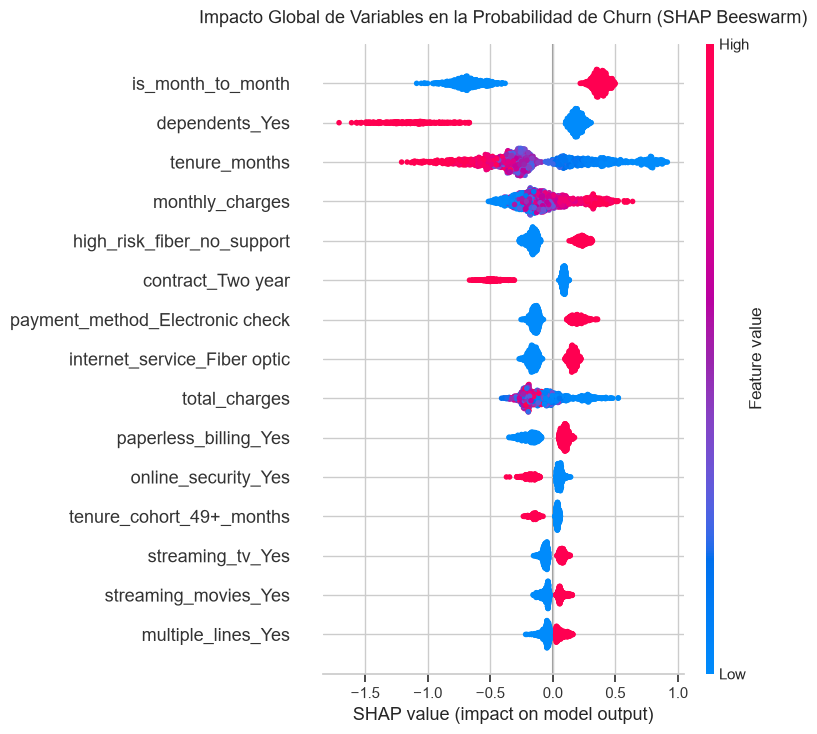

In [7]:
plt.figure(figsize=(10, 8))
# El summary plot tipo beeswarm muestra importancia + dirección + densidad de valores
shap.summary_plot(shap_values, X_test_df, max_display=15, show=False)
plt.title("Impacto Global de Variables en la Probabilidad de Churn (SHAP Beeswarm)", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

### Análisis de Explicabilidad Global (SHAP Beeswarm Plot)

El gráfico de enjambre (Beeswarm) ordena las variables por su contribución neta promedio y revela la dirección y magnitud del impacto de cada atributo en el riesgo de fuga:

1. **Variables con mayor tracción hacia la fuga (Empujan a la derecha, SHAP > 0):**
   * **`is_month_to_month` (Rango alto / Rojo):** Es el driver número uno de deserción. Los clientes sin permanencia contractual acumulan valores SHAP de hasta `+0.50`, duplicando la propensión de abandono frente a quienes poseen contrato anual.
   * **`high_risk_fiber_no_support` y `internet_service_Fiber optic`:** Aparecen en los primeros puestos. La presencia de fibra óptica (especialmente sin soporte técnico) tiene una concentración roja a la derecha, confirmando que la fricción técnica y el mayor cobro en este segmento aceleran la salida.
   * **`monthly_charges` (Valores altos / Rojo):** A mayor cargo mensual facturado, mayor desplazamiento positivo hacia el churn.
   * **`payment_method_Electronic check` y `paperless_billing_Yes`:** Los métodos de pago manuales desasistidos (cheque electrónico) correlacionan con menor fricción para cancelar respecto al débito automático bancario.

2. **Variables de retención y lealtad (Empujan a la izquierda, SHAP < 0):**
   * **`dependents_Yes`:** Presenta un impacto negativo masivo (puntos rojos a la izquierda con SHAP de hasta `-1.6`). Los hogares con cargas familiares muestran una inercia de cambio sumamente alta; alterar la conectividad del hogar genera disrupción familiar.
   * **`tenure_months`:** A mayor antigüedad (puntos rojos/morados), mayor es el blindaje contra la fuga (valores SHAP negativos).
   * **`contract_Two year`:** Tener un contrato a 24 meses actúa como barrera estructural contra el churn (desplazamiento a la izquierda).
   * **`online_security_Yes`:** La contratación de capas adicionales de seguridad incrementa la adherencia (*stickiness*) del cliente.

### Explicabilidad Local — Waterfall Plot para un Cliente Específico en Riesgo

Analizando Cliente Crítico (Fila 1362):
   * Probabilidad Predicha de Churn: 92.13%
   * Realidad Histórica: Fugado


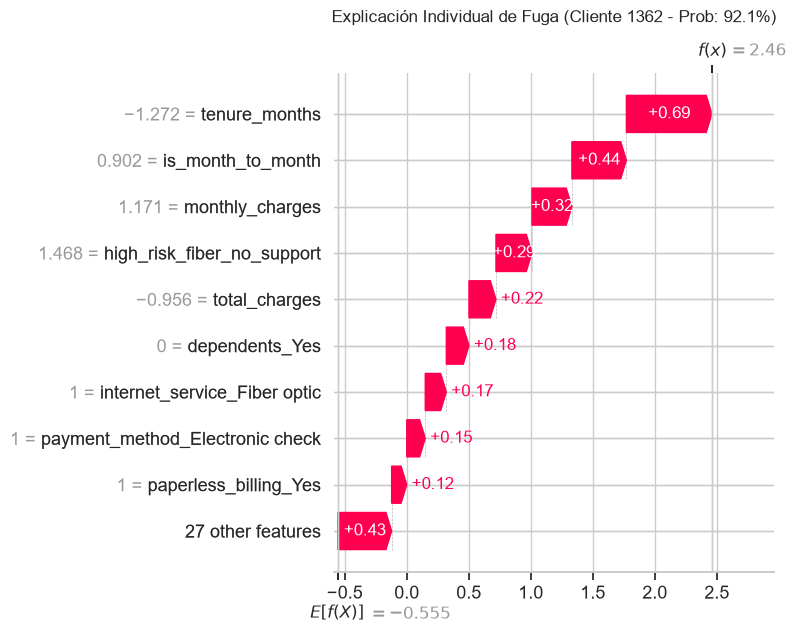

In [8]:
# Buscar el índice del cliente con mayor probabilidad de fuga en X_test
y_test_proba = pipeline.predict_proba(X_test)[:, 1]
idx_cliente_critico = np.argmax(y_test_proba)

prob_fuga = y_test_proba[idx_cliente_critico]
print(f"Analizando Cliente Crítico (Fila {idx_cliente_critico}):")
print(f"   * Probabilidad Predicha de Churn: {prob_fuga:.2%}")
print(f"   * Realidad Histórica: {'Fugado' if y_test.iloc[idx_cliente_critico] == 1 else 'Retenido'}")

# Graficar la cascada de decisión de este cliente
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[idx_cliente_critico], max_display=10, show=False)
plt.title(f"Explicación Individual de Fuga (Cliente {idx_cliente_critico} - Prob: {prob_fuga:.1%})", fontsize=12, pad=15)
plt.tight_layout()
plt.show()

### Diagnóstico Individual: Anatomía de la Fuga del Cliente 1362

El gráfico de cascada descompone la predicción del caso más crítico del conjunto de prueba (**Probabilidad Predicha: 92.13%**, cliente efectivamente fugado):

* **Línea Base Poblacional ($E[f(X)] = -0.555$ en escala log-odds):** Representa el log-odds correspondiente a la tasa natural de churn de la cartera (~26.5%).
* **Factores que detonaron la alerta de deserción:**
  1. **Baja Antigüedad (`tenure_months = -1.272` normalizado):** Al ser un cliente reciente, suma **+0.69** al log-odds.
  2. **Contrato Mes a Mes (`is_month_to_month = 0.902`):** Añade **+0.44** de riesgo inmediato por falta de barreras de salida.
  3. **Factura Elevada (`monthly_charges = 1.171` normalizado):** Paga una tarifa muy superior a la media, sumando **+0.32**.
  4. **Fibra Óptica sin Soporte (`high_risk_fiber_no_support = 1.468`):** Suma **+0.29** de fricción técnica.
  5. **Bajo Consumo Histórico Acumulado (`total_charges = -0.956`):** Agrega **+0.22**.
  6. **Sin Cargas Familiares (`dependents_Yes = 0`):** Añade **+0.18** al no tener la barrera de retención familiar.
  7. **Canales de Facturación (`Electronic check` y `Paperless billing`):** Suman **+0.27** combinados.
* **Resultado Final ($f(x) = 2.46$ log-odds):** 
  $$\text{Probabilidad} = \frac{1}{1 + e^{-2.46}} \approx 92.1\%$$

> **Aplicación Comercial:** Este nivel de detalle permite que el CRM indique tanto la probabilidad de riesgo (92% de riesgo para el caso estudiado) y adicionalmente indica la receta de retención exacta: *migrar de cheque electrónico a débito automático, paquetizar soporte técnico gratuito en su fibra y ofrecer un descuento condicionado a contrato anual*.